# Starter Code

Karate Club Network
Number of nodes: 34
Number of edges: 78
Directed: False

First 10 nodes:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

First 10 edges:
[(0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (0, 6), (0, 7), (0, 8), (0, 10), (0, 11)]


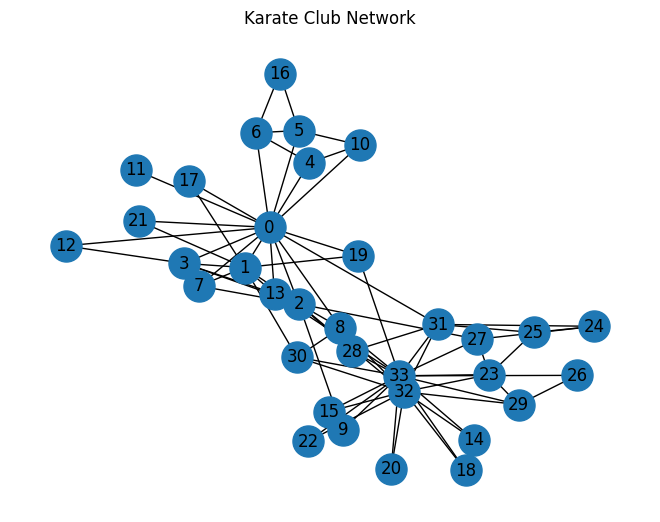

In [ ]:
# Part 1: Load and inspect network
import networkx as nx
from networkx.algorithms import community
import matplotlib.pyplot as plt


G = nx.karate_club_graph()

print("Karate Club Network")
print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())
print("Directed:", G.is_directed())

print("\nFirst 10 nodes:")
print(list(G.nodes())[:10])

print("\nFirst 10 edges:")
print(list(G.edges())[:10])


def visualize_graph(G, title):
    """
    Visualize the graph using a reproducible layout.
    """

    pos = nx.spring_layout(G, seed=42)

    nx.draw(
        G,
        pos,
        with_labels=True,
        node_size=500
    )

    plt.title(title)
    plt.show()


visualize_graph(G, "Karate Club Network")

In [ ]:
# Part 2: Clique Analysis

def clique_analysis(G: nx.Graph) -> int | list:
  # returns max clique size and the largest clique
  maximal_cliques = nx.find_cliques(G) # returns iterator obj
  largest_clique = max(maximal_cliques, key=len)
  return len(largest_clique), largest_clique

clique_analysis(G)



(5, [0, 1, 2, 3, 13])

In [ ]:
# Part 3: Girvan-Newman First Split

def girvan_newman_first_split(G: nx.Graph) -> tuple:
  # returns first community split produced by Girvan-Newman algorithm
  comp = community.girvan_newman(G)
  return next(comp)

girvan_newman_first_split(G)

({0, 1, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 17, 19, 21},
 {2, 8, 9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33})

In [ ]:
# Part 4: Multiple Girvan-Newman Partitions


def girvan_newman_partitions(G: nx.Graph, num_partitions=3) -> list:
  """
  returns list of partitions
  """
  comp = community.girvan_newman(G)
  part_list = []
  for num in range(num_partitions):
    part_list.append(next(comp))

  return part_list

girvan_comms = girvan_newman_partitions(G)

In [ ]:
# Part 5: Modularity

def calculate_modularity(G: nx.Graph, communities: list) -> float:
  return nx.community.modularity(G, communities)

# testing modularity score
girvan_commun = girvan_newman_partitions(G)[0]
calculate_modularity(G, girvan_commun)


0.3476602762317048

In [ ]:
# Part 6: Louvain Community Detection

def louvain_analysis(G: nx.Graph):
  SEED = 42

  return nx.community.louvain_communities(G, seed=SEED)

louv_comms = louvain_analysis(G)
louv_comms

[{1, 2, 3, 7, 12, 13},
 {0, 4, 5, 6, 10, 11, 16, 17, 19, 21},
 {24, 25, 28, 31},
 {8, 9, 14, 15, 18, 20, 22, 23, 26, 27, 29, 30, 32, 33}]

In [ ]:
# Part 7: Compare Community Detection Results

def print_communities(communities):

  for i, community in enumerate(communities, start=1):
    print(f"Community {i}")
    print("Size:", len(community))
    print("Nodes:", sorted(community))
    print()

print("=" * 10 + "Louvain Community Detection" + "="*10)
print_communities(louv_comms)
print("=" * 10 + "Girvan Newman" + "="*10)
print_communities(girvan_comms)

==========Louvain Community Detection==========
Community 1
Size: 6
Nodes: [1, 2, 3, 7, 12, 13]

Community 2
Size: 10
Nodes: [0, 4, 5, 6, 10, 11, 16, 17, 19, 21]

Community 3
Size: 4
Nodes: [24, 25, 28, 31]

Community 4
Size: 14
Nodes: [8, 9, 14, 15, 18, 20, 22, 23, 26, 27, 29, 30, 32, 33]

==========Girvan Newman==========
Community 1
Size: 2
Nodes: [{0, 1, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 17, 19, 21}, {2, 8, 9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33}]

Community 2
Size: 3
Nodes: [{0, 1, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 17, 19, 21}, {32, 33, 2, 8, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31}, {9}]

Community 3
Size: 4
Nodes: [{0, 1, 3, 7, 11, 12, 13, 17, 19, 21}, {32, 33, 2, 8, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31}, {4, 5, 6, 10, 16}, {9}]



# Part 1: Load and Inspect the Network

In [ ]:
print(f"Number of Nodes: {G.number_of_nodes()}")
print(f"Number of Edges: {G.number_of_edges()}")
print(f"Is graph directed: {G.is_directed()}")

Number of Nodes: 34
Number of Edges: 78
Is graph directed: False


1. A node represents a person that is apart of the Karate club.

2. An edge represents a social relationship between two members.

3. Yes, I do think the network contains groups due to there being multiple nodes that have many neighbors but those neighbors are not connected to the other hub node.

4. You should be cautious about identifying communities only from a visualization because some of the nodes could be misclassified as being apart of another group that it is actually not apart of.

# Part 2 - Cliques and Local Cohesion

In [ ]:
clique_res = clique_analysis(G)
print(clique_res)

print(f"Largest clique size: {clique_res[0]}")
print(f"Click of size {clique_res[0]}: {clique_res[1]}")
print(f"Nodes: {clique_res[1]}")

(5, [0, 1, 2, 3, 13])
Largest clique size: 5
Click of size 5: [0, 1, 2, 3, 13]
Nodes: [0, 1, 2, 3, 13]


1. This group is a clique because every node is connected to every other node.

2. No, clique is not the same thing as a community. A clique is a set of nodes where every pair is directly connected. Community is a group of nodes that are more densely connected to one another.

3. Requiring every node in a group to connect to every other node will be too restrictive because the definition of a community is a lot looser and does not conform to one sole idea. For example there are different ways of measuring a community through the Louvain analysis and Girven-Newman analysis.

# Part 3 - Girvan-Newman First Split

In [ ]:
girvan_newman = girvan_newman_first_split(G)
print_communities(girvan_newman)


Community 1
Size: 15
Nodes: [0, 1, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 17, 19, 21]

Community 2
Size: 19
Nodes: [2, 8, 9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]



1. 2 communities were created in the first split

2. Girvan-Newman focuses on edges with high edge betweenness because edges with high edge betweenness tend to be bridges. With this information, we would be able to find the structurally important edges whose removal would fragment the network.

3. If an edge lies on many shortest paths then that edge acts like a bridge within the network.

4. Removing such an edge would only leave the cohesive groups.

# Part 4 - Explore Multiple Girvan-Newman Partitions

In [ ]:
gn_part = girvan_newman_partitions(G)

comm_p = gn_part[2]

# printing community with size of each community
print_communities(gn_part)
for i in range(len(comm_p)):
  print(f"Community {i} size: {len(comm_p[i])}")


Community 1
Size: 2
Nodes: [{0, 1, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 17, 19, 21}, {2, 8, 9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33}]

Community 2
Size: 3
Nodes: [{0, 1, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 17, 19, 21}, {32, 33, 2, 8, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31}, {9}]

Community 3
Size: 4
Nodes: [{0, 1, 3, 7, 11, 12, 13, 17, 19, 21}, {32, 33, 2, 8, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31}, {4, 5, 6, 10, 16}, {9}]

Community 0 size: 10
Community 1 size: 18
Community 2 size: 5
Community 3 size: 1


| Partition | Number of Communities | Community Size |
|-----------|-----------------------|----------------|
| 1         | 2                     | 10, 18         |
| 2         | 3                     | 10, 18, 1      |
| 3         | 4                     | 10, 18, 5, 1   |

1. The number of communites increases as the algorithm continues

2. No, continuing to split the graph does not always produce a more meaningful partition. If we continued to split the graph then every node will be isolated which is meaningless.

3. We need a way to evaluate the quality of a partition because we need a way to tell a meaningful partition vs a meaningless one.

# Part 5 - Modularity

In [ ]:
for i in range(len(gn_part)):
  print(f"Community {i+1} Modularity Score: {calculate_modularity(G, gn_part[i])}")

Community 0 Modularity Score: 0.3476602762317048
Community 1 Modularity Score: 0.3423192968647514
Community 2 Modularity Score: 0.3580611307884035


| Partition       | Number of Communities |
|-----------------|-----------------------|
| Girvan_Newman 1 | 0.3476602762317048    |
| Girvan_Newman 2 | 0.3423192968647514    |
| Girvan_Newman 3 | 0.3580611307884035    |

1. Partition 3 has a higher modularity.

2. A higher modularity value indicates how good a partition is.

3. Modularity is more informative because if we were to only count communities then best communities would just be the ones that are the most split up which doesn't tell us anything on how well they're formed.

4. A larger number of communities does not automatically mean a better partition because it doesn't tell us anything on how the edges are distributed across a partition.  

# Part 6 - Louvain Community Detection

In [ ]:
louvain_p = louvain_analysis(G)
print_communities(louvain_p)
print(f"Modularity: {calculate_modularity(G, louvain_p)}")

Community 1
Size: 6
Nodes: [1, 2, 3, 7, 12, 13]

Community 2
Size: 10
Nodes: [0, 4, 5, 6, 10, 11, 16, 17, 19, 21]

Community 3
Size: 4
Nodes: [24, 25, 28, 31]

Community 4
Size: 14
Nodes: [8, 9, 14, 15, 18, 20, 22, 23, 26, 27, 29, 30, 32, 33]

Modularity: 0.4266224396094526


| Method                       | # of Communities | Community Sizes | Modularity         |
|------------------------------|------------------|-----------------|--------------------|
| Best Girvan-Newman Partition | 3                | 10, 18, 5, 1    | 0.3580611307884035 |
| Louvain                      | 4                | 6, 10, 4, 14    | 0.4266224396094526 |

1. Louvain identified 4 communities

2. No, it is not the same number

3. The Louvain contained the highest modularity.

4. No, both methods do not place every node in the exact same group.

5. Different algorithms will produce different community structures because they have different ways to find a community which may lead to finding sets of nodes for each community. For example, the Louvain algorithm using a greedy approach while Girvan-Newman calculates the edge-betweenness of an edge(s) and deletes them.

# Part 7 - Compare the Algorithms


1. Girvan-Newman uses the edge-betweenness to determine which edges to remove the network.

2. In Louvain, the role of the modularity value is to define how good a community is.

3. The Louvain algorithm produced a higher modularity partition.

4. No not always. This is due to the fact that the algorithms that produce modularity scores use a mathematical heuristic to find partitions but do not have the context of the problem to help make smarter decisions. For example, a lot of social networks will have overlap with the communities since people tend to be involved in more than one community. The algorithm won't have context for what type of network we are working on, it will only apply the heuristic to the input given.

5. Additional information that can help determine if the detected communities are meaningful is to compare the different outputs of the algorithms and check if the values and communities are the same. Another piece of information that can help is to check if the communities follow the actual definition of the nodes and their attributes.

# Part 8 - AI Use Documentation

1. How come Girvan-Newman and Louvain can differ in the communities they produce even though they are using the same network?

2. The AI suggested that this is due to the way the two algorithms detect communities. The two algorithms are not optimizing the same thing. Girvan-Newman repeatedly removes edges that have a high-edge betweenness and then calculates modularity while Louvain calculates modularity at each step. This will lead to Louvain usually reaching a higher modularity.

3. I verified this suggestion by comparing the modularity values between the two algorithms.

4. Since this was a conceptual question, I didn't necessarily use it but it did help me have a better idea when it came to answering some of the questions.

# Part 9 - Reflection

Community detection is more complicated than simply finding groups of connected nodes because finding groups of connected nodes is not relative. You simply look at node A and node B and check if they are connected, then you repeat the process for the rest of the nodes. But community detection is a relative problem. Detecting a community requires checking how tightly tied a group of nodes are compared to everyone else. This can be done with the use of finding the largest edge betweenness and removing the edge(s) with the largest edge betweenness which would just leave the communities. When finding communities, we also need to check how dense the communities are. One way to do this is with the use of a modularity value which compares how dense the connections inside communities are with the expected modularity value of the partition. Neither of these are required when you are trying to find groups of connected nodes.

Two community-detection algorithms may identify different communities on the same network because of the way they search. Girvan-Newman removes edges while Louvain uses a mathematical heuristic to find communities. Maybe Girvan-Newman will remove an edge to a node that the Louvain adds into a community because that edge was never deleted.